# MM HW 06

In [7]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("observations-hw6.txt")

In [8]:
b=8
h1 = 0.075
h2 = 0.4 # [1 - (0.075)(8-0)] / 1

mu_grid = np.linspace(0.5, 7.5, 10000) # a + delta/2 = .5, b - delta/2 = 7.5

LL_count = [] # count of mu potentials


for mu in mu_grid: 
    N_in = np.sum((data >= mu-.5) & (data <= mu+0.5)) # delta/2 = 0.5
    LL_func = N_in*np.log(h1+h2) + (100-N_in)*np.log(h1) # analytically found
    LL_count.append(LL_func)


best_index = np.argmax(LL_count) # return index of larget value (what point is the max)
mu_hat = mu_grid[best_index] # return largest value (what mu is associated with that point)

print(mu_hat)

6.491199119911991


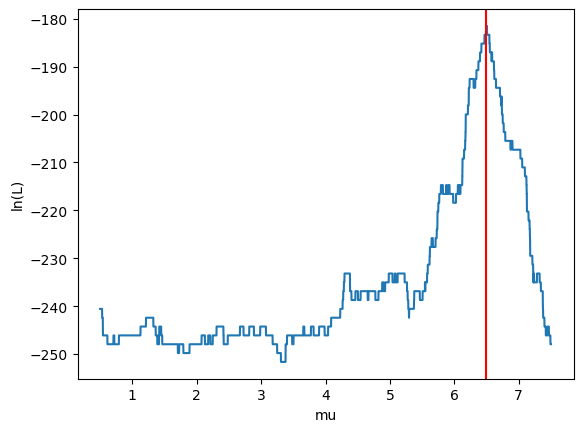

In [16]:
plt.plot(mu_grid, LL_count)
plt.xlabel('mu')
plt.ylabel('ln(L)')
plt.axvline(mu_hat, c='r')
plt.show()

Part 3 completed. Yes mu is concentrated at the peak, almost the max...

In [23]:
from scipy.stats import chi2

def chi2_ppf(beta):
    return chi2.ppf(beta, df=1)

chi2_value = chi2_ppf(.99)

LL_max = LL_count[best_index]
cutoff = LL_max - chi2_value / 2 # slicing the array

valid = LL_count >= cutoff # confirm slice follows inequality

mu_CI = mu_grid[valid] # interval array

mu_low = mu_CI[0] # lower bound
mu_high = mu_CI[-1] # upper bound

print("mu_hat =", mu_hat)
print("99% CI =", mu_low, "to", mu_high)

mu_hat = 6.491199119911991
99% CI = 6.466696669666966 to 6.543004300430042


Mission complete